# PCA

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

In [2]:
dataset = load_iris()
df = pd.DataFrame(dataset.data,columns=dataset.feature_names)
df['target'] = dataset.target

In [3]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


<Axes: >

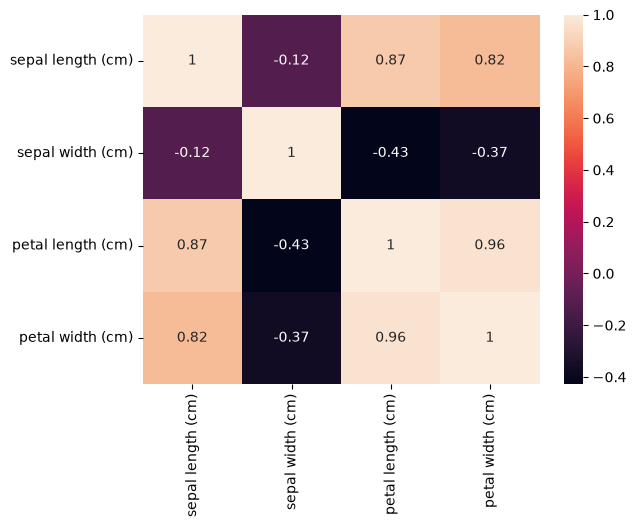

In [4]:
import seaborn as sns
sns.heatmap(df.iloc[:,:-1].corr(),annot=True)

In [5]:
X = df.iloc[:,:-1]
Y= df.iloc[:,-1]

In [6]:
from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(X)

In [7]:
cov = (X_scaled.T@X_scaled)/(len(X_scaled)-1)
values,vectors = np.linalg.eigh(cov)

In [8]:
values

array([0.02085386, 0.14774182, 0.9201649 , 2.93808505])

In [9]:
explained_var = []

for value in values:
    explained_var.append(value*100/sum(values))

explained_var

[np.float64(0.5178709107154877),
 np.float64(3.6689218892828768),
 np.float64(22.850761786701757),
 np.float64(72.96244541329989)]

In [11]:
X_reduced = X_scaled@vectors[:,2:4]
reduced_df = pd.DataFrame(X_reduced,columns=['X1','X2'])
reduced_df['target'] = df['target']

<Axes: >

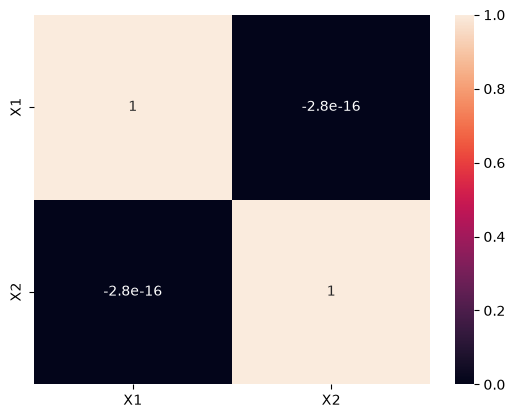

In [12]:
sns.heatmap(reduced_df.iloc[:,:-1].corr(),annot=True)

In [13]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

In [14]:
X_reduced

array([[-2.26470281,  0.4800266 ],
       [-2.08096115, -0.67413356],
       [-2.36422905, -0.34190802],
       [-2.29938422, -0.59739451],
       [-2.38984217,  0.64683538],
       [-2.07563095,  1.48917752],
       [-2.44402884,  0.0476442 ],
       [-2.23284716,  0.22314807],
       [-2.33464048, -1.11532768],
       [-2.18432817, -0.46901356],
       [-2.1663101 ,  1.04369065],
       [-2.32613087,  0.13307834],
       [-2.2184509 , -0.72867617],
       [-2.6331007 , -0.96150673],
       [-2.1987406 ,  1.86005711],
       [-2.26221453,  2.68628449],
       [-2.2075877 ,  1.48360936],
       [-2.19034951,  0.48883832],
       [-1.898572  ,  1.40501879],
       [-2.34336905,  1.12784938],
       [-1.914323  ,  0.40885571],
       [-2.20701284,  0.92412143],
       [-2.7743447 ,  0.45834367],
       [-1.81866953,  0.08555853],
       [-2.22716331,  0.13725446],
       [-1.95184633, -0.62561859],
       [-2.05115137,  0.24216355],
       [-2.16857717,  0.52714953],
       [-2.13956345,

In [15]:
pca.explained_variance_ratio_

array([0.72962445, 0.22850762])